## 1. Imports & Configuration

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Visual style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Path to dataset (update if your file is located elsewhere)
DATA_PATH = r"C:\Users\admin\Downloads\cicids2017_cleaned.csv"


## 2. Load Dataset

In [4]:
df = pd.read_csv(DATA_PATH)

# Strip any stray leading/trailing whitespace from column names
df.columns = df.columns.str.strip()

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Dataset shape: 2,520,751 rows x 53 columns


,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack Type
0,22,1266342,41,2664,456,0,64.975610,109.864573,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
1,22,1319353,41,2664,456,0,64.975610,109.864573,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
2,22,160,1,0,0,0,0.000000,0.000000,0,0,...,243,0,32,0.0,0,0,0.0,0,0,Normal Traffic
3,22,1303488,41,2728,456,0,66.536585,110.129945,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
4,35396,77,1,0,0,0,0.000000,0.000000,0,0,...,290,0,32,0.0,0,0,0.0,0,0,Normal Traffic


## 3. Initial Data Exploration

In [5]:
# Column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2520751 entries, 0 to 2520750
Data columns (total 53 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Length of Fwd Packets  int64  
 4   Fwd Packet Length Max        int64  
 5   Fwd Packet Length Min        int64  
 6   Fwd Packet Length Mean       float64
 7   Fwd Packet Length Std        float64
 8   Bwd Packet Length Max        int64  
 9   Bwd Packet Length Min        int64  
 10  Bwd Packet Length Mean       float64
 11  Bwd Packet Length Std        float64
 12  Flow Bytes/s                 float64
 13  Flow Packets/s               float64
 14  Flow IAT Mean                float64
 15  Flow IAT Std                 float64
 16  Flow IAT Max                 int64  
 17  Flow IAT Min                 int64  
 18  Fwd IAT Total                int64  
 19  

In [6]:
# Basic statistical summary of numeric features
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Destination Port,2520751.0,8.690744e+03,1.901294e+04,0.000000e+00,53.000000,80.000000,4.430000e+02,6.553500e+04
Flow Duration,2520751.0,1.659032e+07,3.523140e+07,-1.300000e+01,208.000000,50620.000000,5.332968e+06,1.200000e+08
Total Fwd Packets,2520751.0,1.025880e+01,7.943824e+02,1.000000e+00,2.000000,2.000000,6.000000e+00,2.197590e+05
Total Length of Fwd Packets,2520751.0,6.065243e+02,1.011595e+04,0.000000e+00,12.000000,66.000000,3.320000e+02,1.290000e+07
Fwd Packet Length Max,2520751.0,2.311993e+02,7.563122e+02,0.000000e+00,6.000000,40.000000,2.020000e+02,2.482000e+04
Fwd Packet Length Min,2520751.0,1.920377e+01,6.079887e+01,0.000000e+00,0.000000,2.000000,3.700000e+01,2.325000e+03
Fwd Packet Length Mean,2520751.0,6.350189e+01,1.955512e+02,0.000000e+00,6.000000,36.250000,5.200000e+01,5.940857e+03
Fwd Packet Length Std,2520751.0,7.732029e+01,2.968824e+02,0.000000e+00,0.000000,0.000000,7.419280e+01,7.125597e+03
Bwd Packet Length Max,2520751.0,9.749253e+02,2.038152e+03,0.000000e+00,6.000000,97.000000,7.460000e+02,1.953000e+04
Bwd Packet Length Min,2520751.0,4.316019e+01,7.088017e+01,0.000000e+00,0.000000,0.000000,8.200000e+01,2.896000e+03


In [7]:
# Check for missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing if not missing.empty else "None — dataset is already clean.")


Columns with missing values:
None — dataset is already clean.


In [8]:
# Check for infinite values (should already be handled, but verify)
inf_counts = np.isinf(df.select_dtypes(include=[np.number])).sum()
inf_counts = inf_counts[inf_counts > 0]
print("Columns with infinite values:")
print(inf_counts if not inf_counts.empty else "None — dataset is already clean.")


Columns with infinite values:
None — dataset is already clean.


In [9]:
# Check for duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")


Duplicate rows: 161


In [10]:
# Target column overview
print("Attack Type value counts:")
print(df["Attack Type"].value_counts())


Attack Type value counts:
Attack Type
Normal Traffic    2095057
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution — Attack Type

C:\Users\admin\AppData\Local\Temp\ipykernel_3140\3066870414.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y="Attack Type", order=order, palette="viridis")


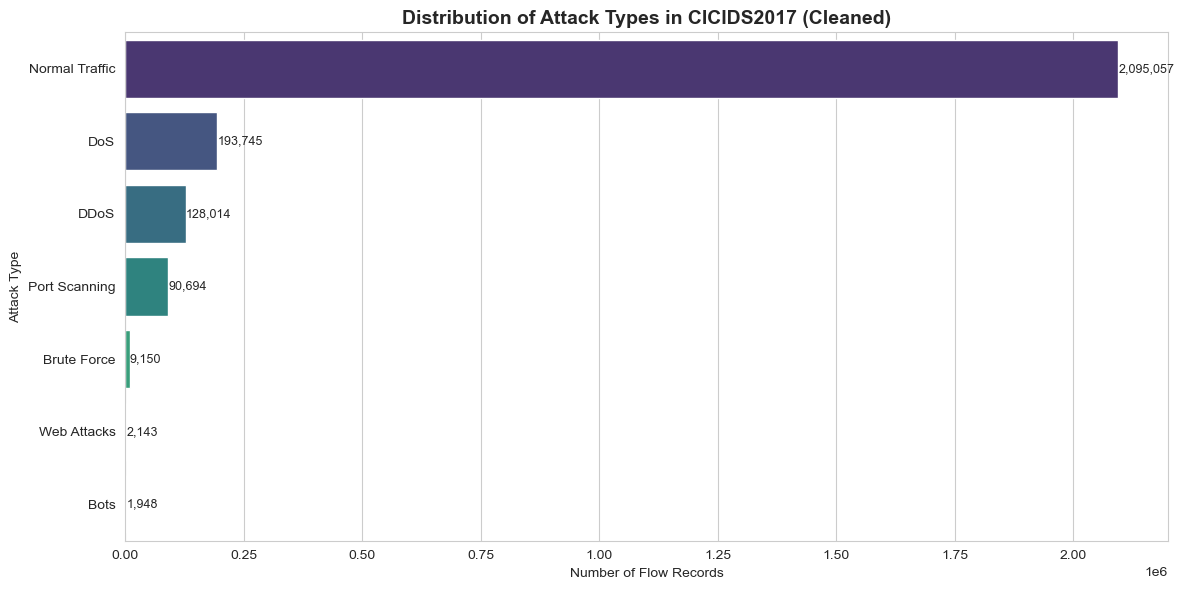

In [11]:
plt.figure(figsize=(12, 6))
order = df["Attack Type"].value_counts().index
ax = sns.countplot(data=df, y="Attack Type", order=order, palette="viridis")
ax.set_title("Distribution of Attack Types in CICIDS2017 (Cleaned)")
ax.set_xlabel("Number of Flow Records")
ax.set_ylabel("Attack Type")
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 500, p.get_y() + p.get_height()/2,
            f"{int(width):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


In [12]:
print(df["Attack Type"].unique())

['Normal Traffic' 'Port Scanning' 'Web Attacks' 'Brute Force' 'DDoS'
 'Bots' 'DoS']


### 4.2 Binary Reframing — Normal vs Abnormal

Binary Label
Normal      2095057
Abnormal     425694
Name: count, dtype: int64


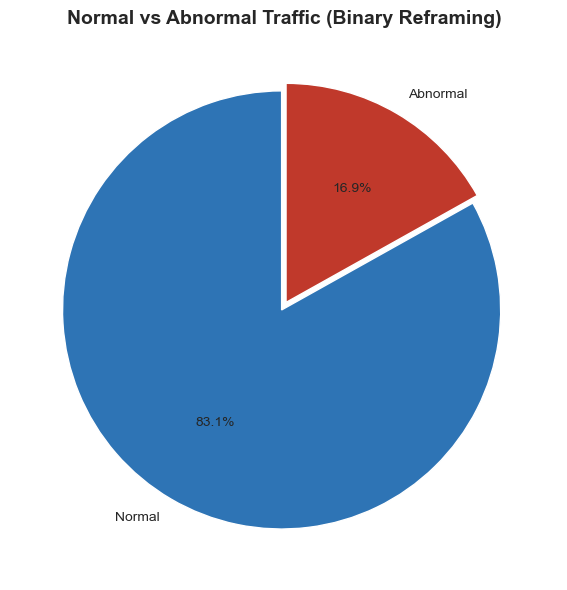


Class imbalance ratio (Normal : Abnormal) = 4.92 : 1


In [13]:
df["Binary Label"] = df["Attack Type"].apply(
    lambda x: "Normal" if x == "Normal Traffic" else "Abnormal"
)

counts = df["Binary Label"].value_counts()
print(counts)  # should show 2 rows: Normal and Abnormal

plt.figure(figsize=(6, 6))
colors = ["#2E74B5", "#C0392B"]
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=colors,
        startangle=90, explode=(0.02, 0.02))
plt.title("Normal vs Abnormal Traffic (Binary Reframing)")
plt.tight_layout()
plt.show()

print(f"\nClass imbalance ratio (Normal : Abnormal) = "
      f"{counts['Normal'] / counts['Abnormal']:.2f} : 1")

### 4.3 Key Traffic Features by Class

C:\Users\admin\AppData\Local\Temp\ipykernel_3140\3844727500.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="Binary Label", y=feature, ax=axes[i],
C:\Users\admin\AppData\Local\Temp\ipykernel_3140\3844727500.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="Binary Label", y=feature, ax=axes[i],
C:\Users\admin\AppData\Local\Temp\ipykernel_3140\3844727500.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="Binary Label", y=feature, ax=axes[i],
C:\Users\admin\AppData\Local\Temp\ipykernel

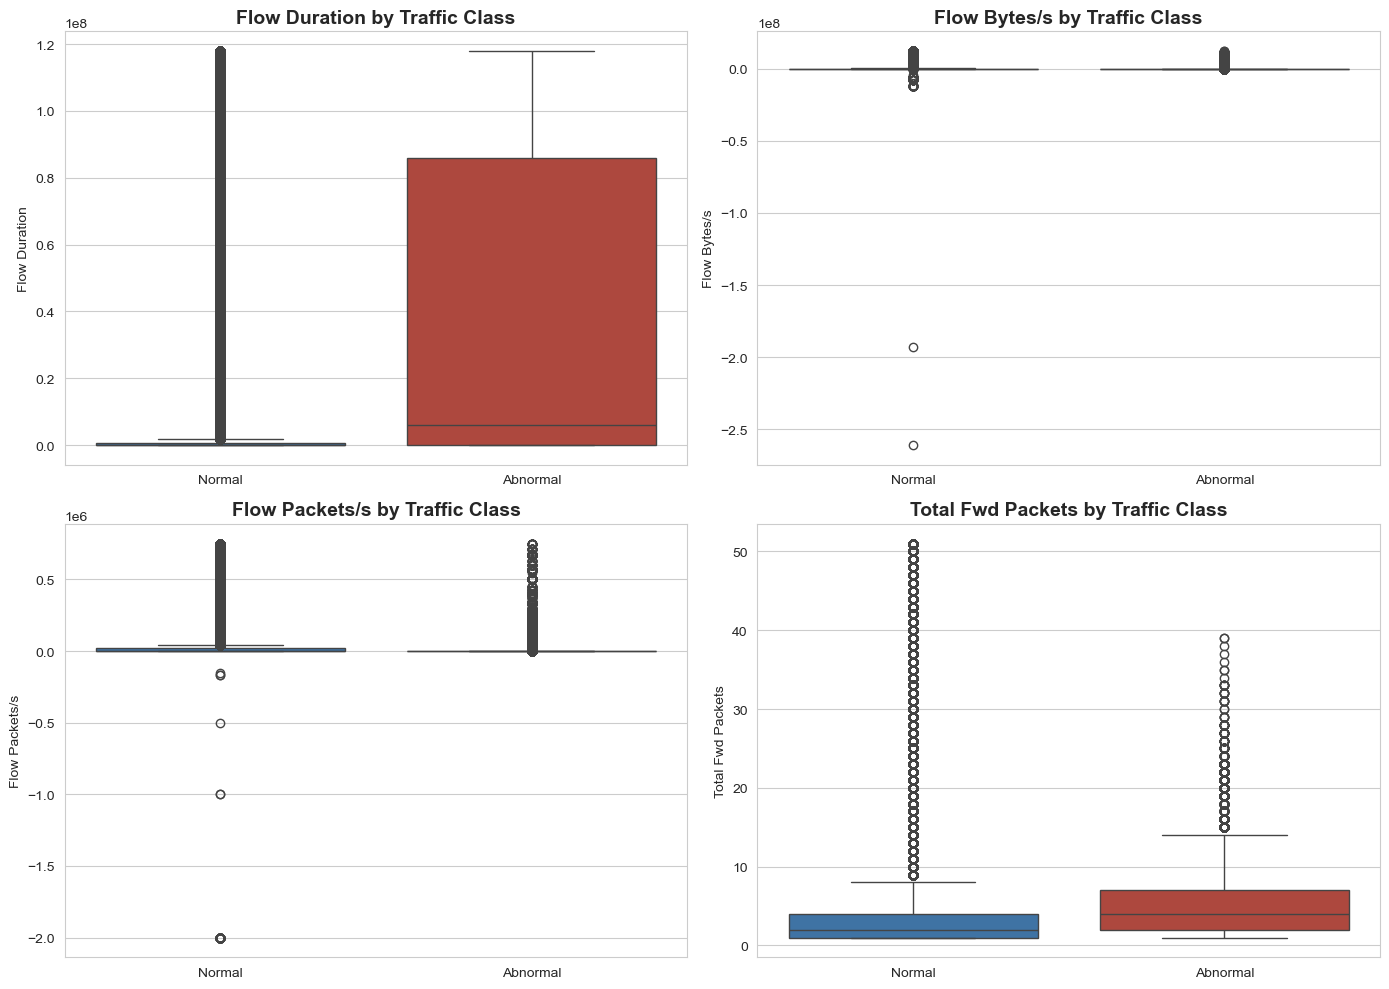

In [14]:
key_features = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Total Fwd Packets"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    # Clip extreme outliers at the 99th percentile purely for visualisation clarity
    upper = df[feature].quantile(0.99)
    plot_df = df[df[feature] <= upper]

    sns.boxplot(data=plot_df, x="Binary Label", y=feature, ax=axes[i],
                palette=["#2E74B5", "#C0392B"])
    axes[i].set_title(f"{feature} by Traffic Class")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()


### 4.4 Feature Correlation Heatmap

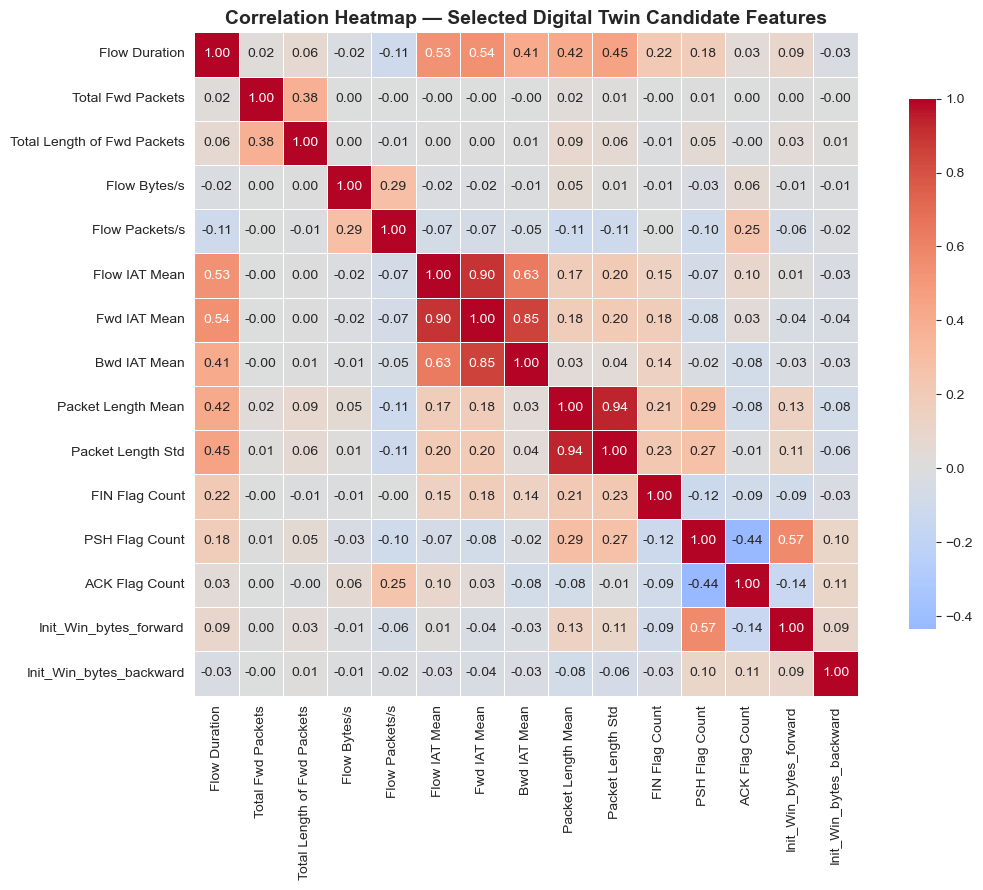

In [15]:
# Use a representative subset of numeric features to keep the heatmap readable
corr_features = [
    "Flow Duration", "Total Fwd Packets", "Total Length of Fwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Fwd IAT Mean",
    "Bwd IAT Mean", "Packet Length Mean", "Packet Length Std",
    "FIN Flag Count", "PSH Flag Count", "ACK Flag Count",
    "Init_Win_bytes_forward", "Init_Win_bytes_backward"
]
corr_features = [f for f in corr_features if f in df.columns]

plt.figure(figsize=(12, 9))
corr_matrix = df[corr_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap — Selected Digital Twin Candidate Features")
plt.tight_layout()
plt.show()

### 4.5 Flow Duration Distribution — Normal vs Abnormal (Density Plot)

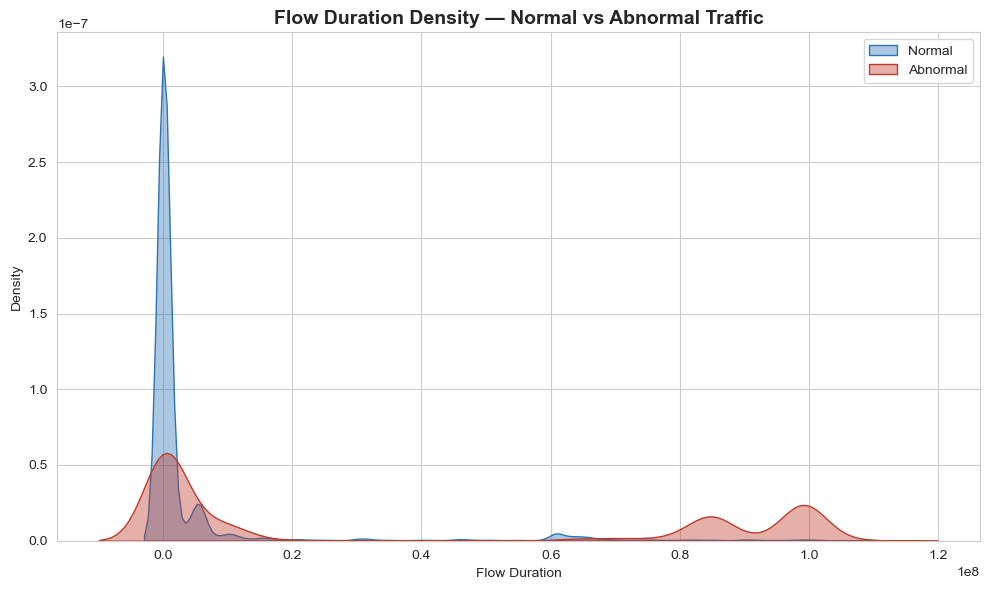

In [16]:
plt.figure(figsize=(10, 6))
upper = df["Flow Duration"].quantile(0.95)
plot_df = df[df["Flow Duration"] <= upper]

sns.kdeplot(data=plot_df[plot_df["Binary Label"] == "Normal"], x="Flow Duration",
            label="Normal", fill=True, alpha=0.4, color="#2E74B5")
sns.kdeplot(data=plot_df[plot_df["Binary Label"] == "Abnormal"], x="Flow Duration",
            label="Abnormal", fill=True, alpha=0.4, color="#C0392B")
plt.title("Flow Duration Density — Normal vs Abnormal Traffic")
plt.xlabel("Flow Duration")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Data Preprocessing

In [17]:
# Encode binary label: Normal = 0, Abnormal = 1 (Abnormal is the "positive"/alert class)
label_encoder = LabelEncoder()
df["Label_Encoded"] = label_encoder.fit_transform(df["Binary Label"])
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))


{'Abnormal': np.int64(0), 'Normal': np.int64(1)}


In [18]:
# Drop non-feature / leakage columns
drop_cols = ["Attack Type", "Binary Label", "Label_Encoded"]
X = df.drop(columns=drop_cols)
y = df["Label_Encoded"]

# Keep only numeric columns as features
X = X.select_dtypes(include=[np.number])

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")


Feature matrix shape: (2520751, 52)
Target vector shape: (2520751,)


In [19]:
# Train/test split — stratified to preserve class balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set:     {X_test.shape[0]:,} rows")


Training set: 1,890,563 rows
Test set:     630,188 rows


In [20]:
# Feature scaling (fit on training data only, to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 6. Digital Twin Representation Layer

In [21]:
class DigitalTwin:
    """
    A simplified software Digital Twin for TwinShield.

    Responsibility: receive raw network flow records and expose a reduced,
    security-relevant feature representation for the detection model —
    concentrating on traffic behaviour, communication activity, and
    network activity levels (proposal Section 5.3), rather than every
    raw feature available in the source data.
    """

    # Features the twin selects for behavioural monitoring
    TRACKED_FEATURES = [
        "Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Flow Packets/s",
        "Flow IAT Mean", "Fwd IAT Mean", "Bwd IAT Mean",
        "Packet Length Mean", "Packet Length Std",
        "FIN Flag Count", "PSH Flag Count", "ACK Flag Count",
        "Init_Win_bytes_forward", "Init_Win_bytes_backward"
    ]

    def __init__(self, feature_columns=None):
        self.feature_columns = feature_columns or self.TRACKED_FEATURES

    def represent(self, raw_flow_df: pd.DataFrame) -> pd.DataFrame:
        """Return the twin's tracked-feature representation of raw traffic."""
        available = [c for c in self.feature_columns if c in raw_flow_df.columns]
        return raw_flow_df[available].copy()


# Instantiate the Digital Twin and build its representation of the traffic
twin = DigitalTwin()
X_train_twin = twin.represent(X_train)
X_test_twin = twin.represent(X_test)

print(f"Digital Twin tracks {len(twin.feature_columns)} features:")
print(twin.feature_columns)


Digital Twin tracks 14 features:
['Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Fwd IAT Mean', 'Bwd IAT Mean', 'Packet Length Mean', 'Packet Length Std', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward']


In [22]:
# Scale the twin's reduced feature representation (used by the TwinShield model below)
twin_scaler = StandardScaler()
X_train_twin_scaled = twin_scaler.fit_transform(X_train_twin)
X_test_twin_scaled = twin_scaler.transform(X_test_twin)


## 7. Baseline Detection Model

In [23]:
baseline_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_scaled, y_train)

y_pred_baseline = baseline_model.predict(X_test_scaled)
print("Baseline model trained on full feature set (no Digital Twin).")


Baseline model trained on full feature set (no Digital Twin).


## 8. TwinShield Detection Model (Random Forest)

In [24]:
twinshield_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"  # accounts for class imbalance seen in Section 4.2
)
twinshield_model.fit(X_train_twin_scaled, y_train)

y_pred_twinshield = twinshield_model.predict(X_test_twin_scaled)
y_proba_twinshield = twinshield_model.predict_proba(X_test_twin_scaled)[:, 1]

print("TwinShield model trained on Digital Twin's reduced feature representation.")


TwinShield model trained on Digital Twin's reduced feature representation.


## 9. Model Evaluation

In [25]:
def evaluate_model(y_true, y_pred, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    fpr = fp / (fp + tn)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "False Positive Rate": fpr,
    }
    return metrics


baseline_metrics = evaluate_model(y_test, y_pred_baseline, "Baseline (Logistic Regression)")
twinshield_metrics = evaluate_model(y_test, y_pred_twinshield, "TwinShield (Random Forest + Digital Twin)")

results_df = pd.DataFrame([baseline_metrics, twinshield_metrics]).set_index("Model")
results_df.round(4)


,Accuracy,Precision,Recall,F1 Score,False Positive Rate
Model,,,,,
Baseline (Logistic Regression),0.9553,0.9700,0.9764,0.9732,0.1485
TwinShield (Random Forest + Digital Twin),0.9977,0.9988,0.9984,0.9986,0.0061


### 9.1 Confusion Matrices

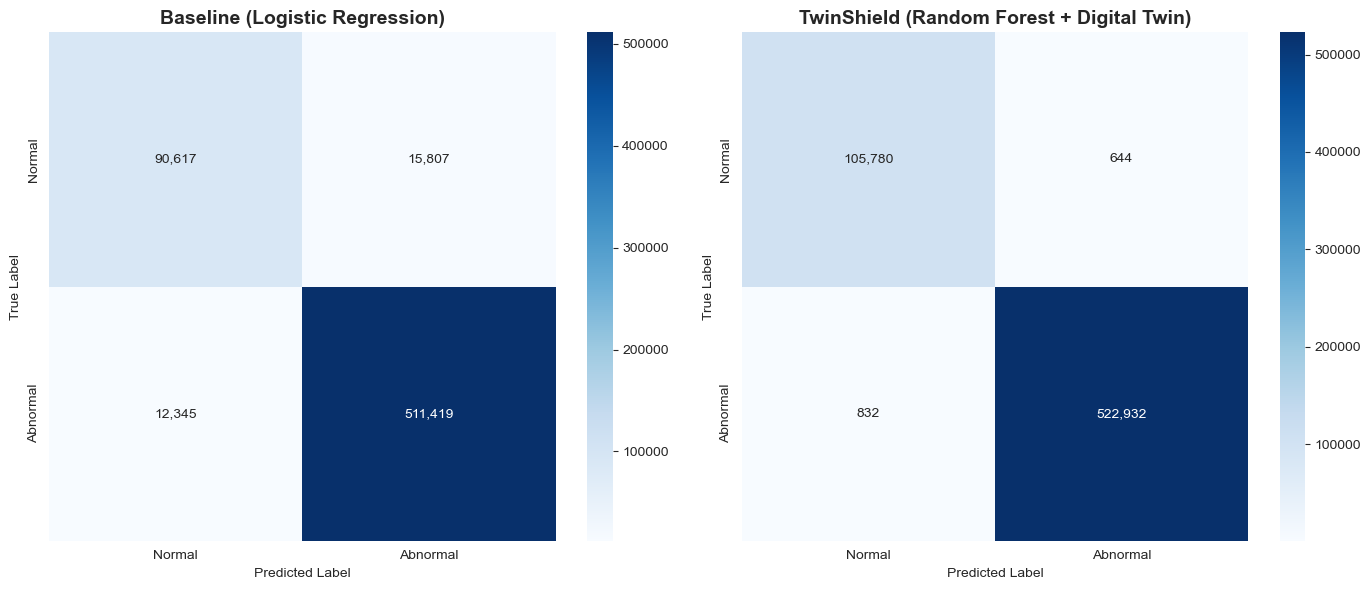

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, y_pred, title in zip(
    axes,
    [y_pred_baseline, y_pred_twinshield],
    ["Baseline (Logistic Regression)", "TwinShield (Random Forest + Digital Twin)"]
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Abnormal"],
                yticklabels=["Normal", "Abnormal"])
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()


### 9.2 Classification Report — TwinShield Model

In [27]:
print(classification_report(y_test, y_pred_twinshield,
                              target_names=["Normal", "Abnormal"]))


              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99    106424
    Abnormal       1.00      1.00      1.00    523764

    accuracy                           1.00    630188
   macro avg       1.00      1.00      1.00    630188
weighted avg       1.00      1.00      1.00    630188



### 9.3 ROC Curve — TwinShield Model

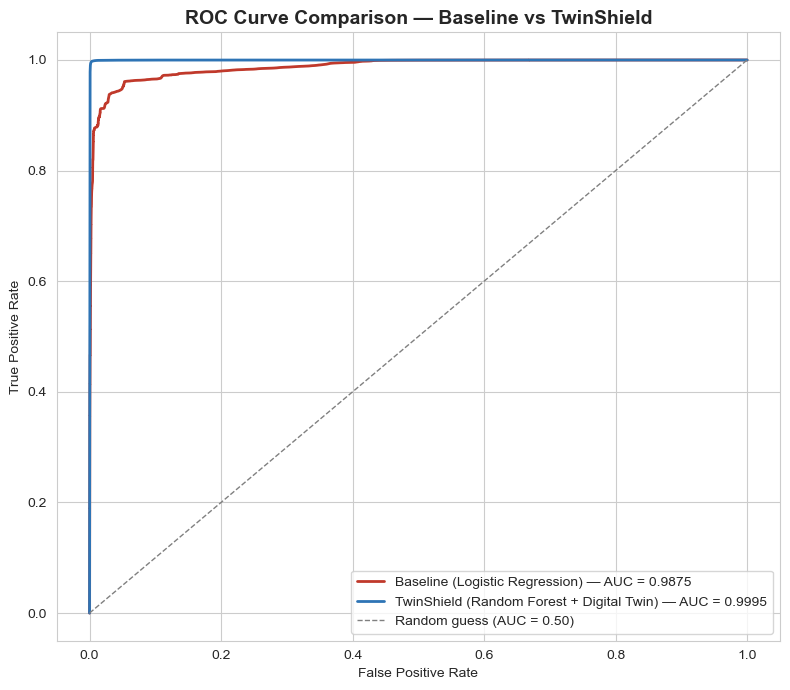

Baseline AUC:   0.9875
TwinShield AUC: 0.9995
AUC improvement: +0.0119


In [32]:
# Baseline probabilities (needed for ROC comparison — predict() alone isn't enough)
y_proba_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]
# ROC curves for both models
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_proba_baseline)
roc_auc_baseline = auc(fpr_baseline, tpr_baseline)

fpr_twinshield, tpr_twinshield, _ = roc_curve(y_test, y_proba_twinshield)
roc_auc_twinshield = auc(fpr_twinshield, tpr_twinshield)

plt.figure(figsize=(8, 7))

plt.plot(fpr_baseline, tpr_baseline, color="#C0392B", lw=2,
         label=f"Baseline (Logistic Regression) — AUC = {roc_auc_baseline:.4f}")
plt.plot(fpr_twinshield, tpr_twinshield, color="#2E74B5", lw=2,
         label=f"TwinShield (Random Forest + Digital Twin) — AUC = {roc_auc_twinshield:.4f}")
plt.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="Random guess (AUC = 0.50)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Baseline vs TwinShield")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Baseline AUC:   {roc_auc_baseline:.4f}")
print(f"TwinShield AUC: {roc_auc_twinshield:.4f}")
print(f"AUC improvement: {roc_auc_twinshield - roc_auc_baseline:+.4f}")

## 10. Baseline vs TwinShield Comparison

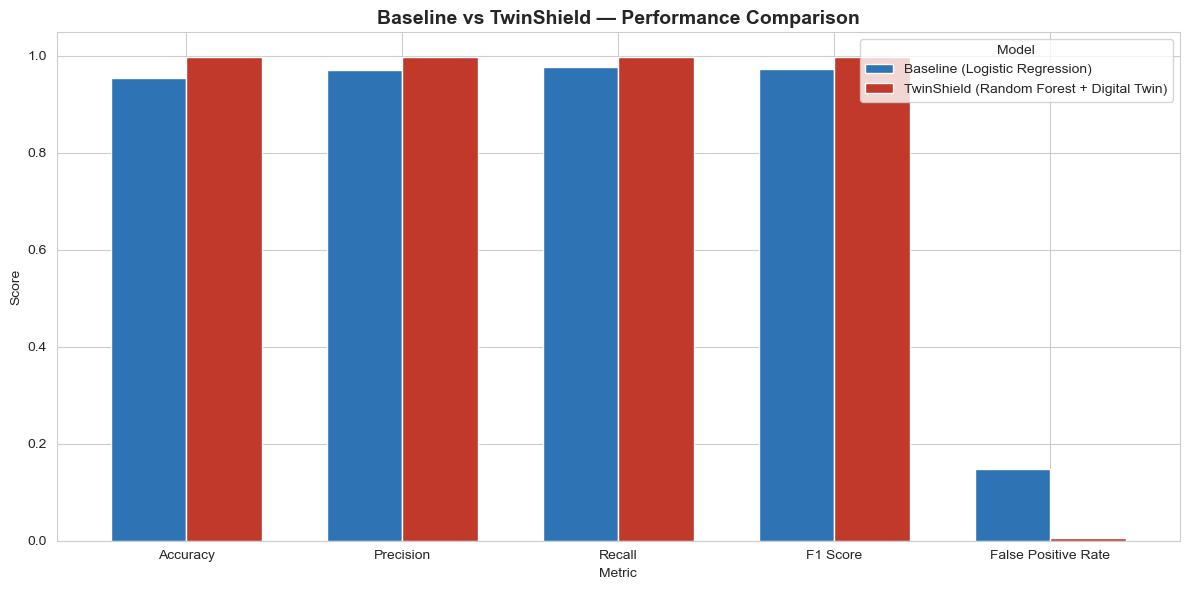

In [29]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "False Positive Rate"]
plot_df = results_df[metrics_to_plot].T

ax = plot_df.plot(kind="bar", figsize=(12, 6),
                   color=["#2E74B5", "#C0392B"], width=0.7)
ax.set_title("Baseline vs TwinShield — Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [30]:
improvement = (results_df.loc["TwinShield (Random Forest + Digital Twin)"]
               - results_df.loc["Baseline (Logistic Regression)"])
print("Change in each metric — TwinShield relative to Baseline:")
print("(positive = improvement, except False Positive Rate where lower is better)\n")
print(improvement.round(4))


Change in each metric — TwinShield relative to Baseline:
(positive = improvement, except False Positive Rate where lower is better)

Accuracy               0.0423
Precision              0.0288
Recall                 0.0220
F1 Score               0.0254
False Positive Rate   -0.1425
dtype: float64


## 11. Feature Importance (TwinShield / Random Forest)

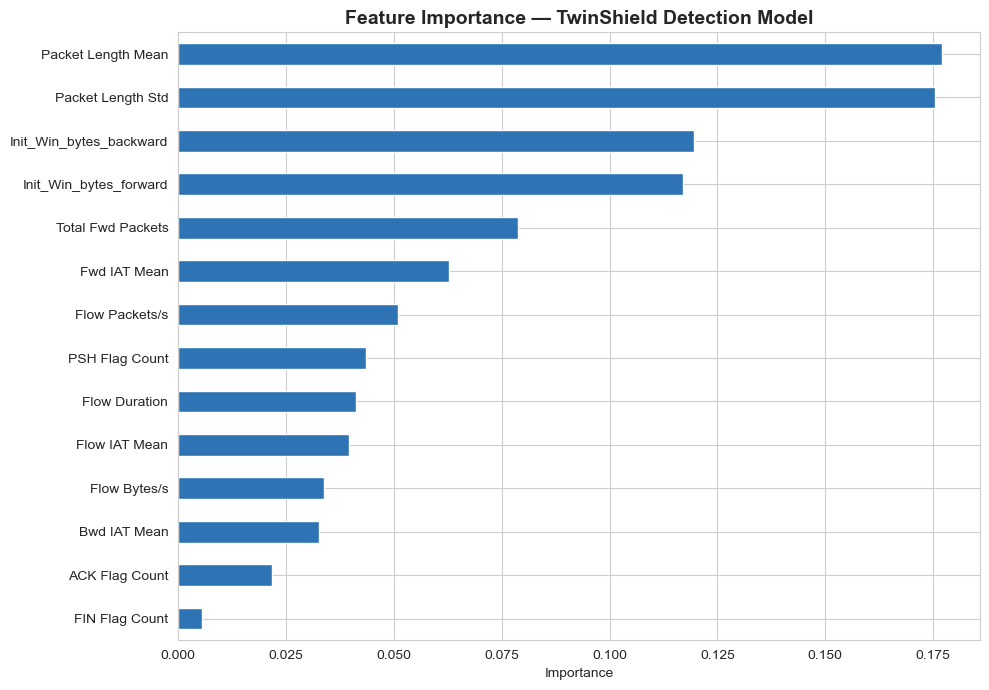

In [31]:
importances = pd.Series(
    twinshield_model.feature_importances_,
    index=twin.feature_columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
importances.plot(kind="barh", color="#2E74B5")
plt.title("Feature Importance — TwinShield Detection Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
